# Tổng quan về dữ liệu

## 1. Metadata

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('../ESC-50-master/meta/esc50.csv')

In [4]:
df.head(5)

,filename,fold,target,category,esc10,src_file,take
0,1-100032-A-0.wav,1,0,dog,True,100032,A
1,1-100038-A-14.wav,1,14,chirping_birds,False,100038,A
2,1-100210-A-36.wav,1,36,vacuum_cleaner,False,100210,A
3,1-100210-B-36.wav,1,36,vacuum_cleaner,False,100210,B
4,1-101296-A-19.wav,1,19,thunderstorm,False,101296,A


In [7]:
print(df.shape)
df.info()

(2000, 7)
<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   filename  2000 non-null   str  
 1   fold      2000 non-null   int64
 2   target    2000 non-null   int64
 3   category  2000 non-null   str  
 4   esc10     2000 non-null   bool 
 5   src_file  2000 non-null   int64
 6   take      2000 non-null   str  
dtypes: bool(1), int64(3), str(3)
memory usage: 95.8 KB


In [8]:
print("Số file âm thanh trong tập dữ liệu:", df.shape[0])
print("Số lớp phân loại trong tập dữ liệu:", df['category'].nunique())
print("Số folder trong tập dữ liệu:", df['fold'].nunique())

Số file âm thanh trong tập dữ liệu: 2000
Số lớp phân loại trong tập dữ liệu: 50
Số folder trong tập dữ liệu: 5


<function matplotlib.pyplot.show(close=None, block=None)>

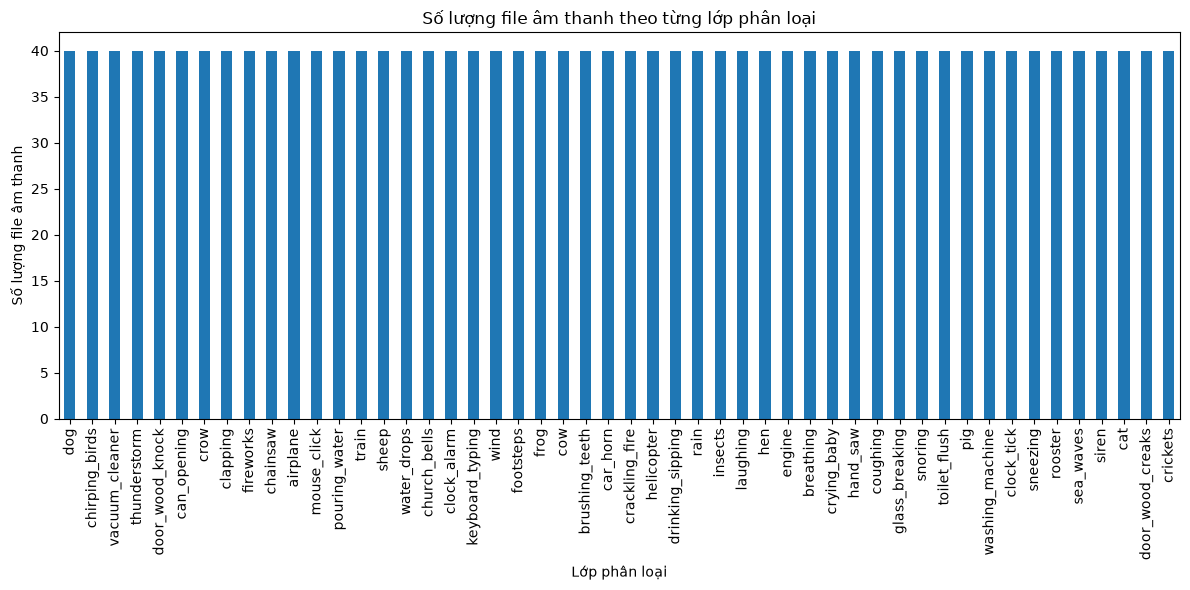

In [14]:
class_counts = df['category'].value_counts()

plt.figure(figsize=(12, 6))
class_counts.plot(kind='bar')
plt.title('Số lượng file âm thanh theo từng lớp phân loại')
plt.xlabel('Lớp phân loại')
plt.ylabel('Số lượng file âm thanh')
plt.tight_layout()
plt.show

In [16]:
fold_counts = df['fold'].value_counts()
display(fold_counts)
fold_class_counts = pd.crosstab(df['fold'], df['category'])
display(fold_class_counts)

fold
1    400
2    400
3    400
4    400
5    400
Name: count, dtype: int64

category,airplane,breathing,brushing_teeth,can_opening,car_horn,cat,chainsaw,chirping_birds,church_bells,clapping,...,siren,sneezing,snoring,thunderstorm,toilet_flush,train,vacuum_cleaner,washing_machine,water_drops,wind
fold,,,,,,,,,,,,,,,,,,,,,
1,8,8,8,8,8,8,8,8,8,8,...,8,8,8,8,8,8,8,8,8,8
2,8,8,8,8,8,8,8,8,8,8,...,8,8,8,8,8,8,8,8,8,8
3,8,8,8,8,8,8,8,8,8,8,...,8,8,8,8,8,8,8,8,8,8
4,8,8,8,8,8,8,8,8,8,8,...,8,8,8,8,8,8,8,8,8,8
5,8,8,8,8,8,8,8,8,8,8,...,8,8,8,8,8,8,8,8,8,8


## Audio

In [17]:
import soundfile as sf

In [28]:
rows = []
for f in df['filename']:
    info = sf.info('../ESC-50-master/audio/' + f)
    rows.append({'filename': f, 'samplerate': info.samplerate, 'channels': info.channels, 'frames': info.frames, 'duration': info.duration})

info_df = pd.DataFrame(rows)
info_df[["samplerate","channels","frames","duration"]].nunique()

samplerate    1
channels      1
frames        1
duration      1
dtype: int64

In [29]:
print(info_df['samplerate'].unique())     
print(info_df['channels'].unique())        
print(info_df['frames'].unique())          
print(info_df['duration'].unique())        

[44100]
[1]
[220500]
[5.]


In [34]:
import librosa
import seaborn as sns
from tqdm import tqdm


In [35]:
AUDIO_DIR = '../ESC-50-master/audio/'
SR, N_FFT, HOP, N_MELS = 22050, 1024, 512, 128

def load_audio(fname):
    y, _ = librosa.load(AUDIO_DIR + fname, sr=SR)
    return y

def logmel(y):
    S = librosa.feature.melspectrogram(y=y, sr=SR, n_fft=N_FFT,
                                       hop_length=HOP, n_mels=N_MELS)
    return librosa.power_to_db(S)         

cats = (df.drop_duplicates('target')
          .sort_values('target')[['target', 'category', 'filename']]
          .reset_index(drop=True))

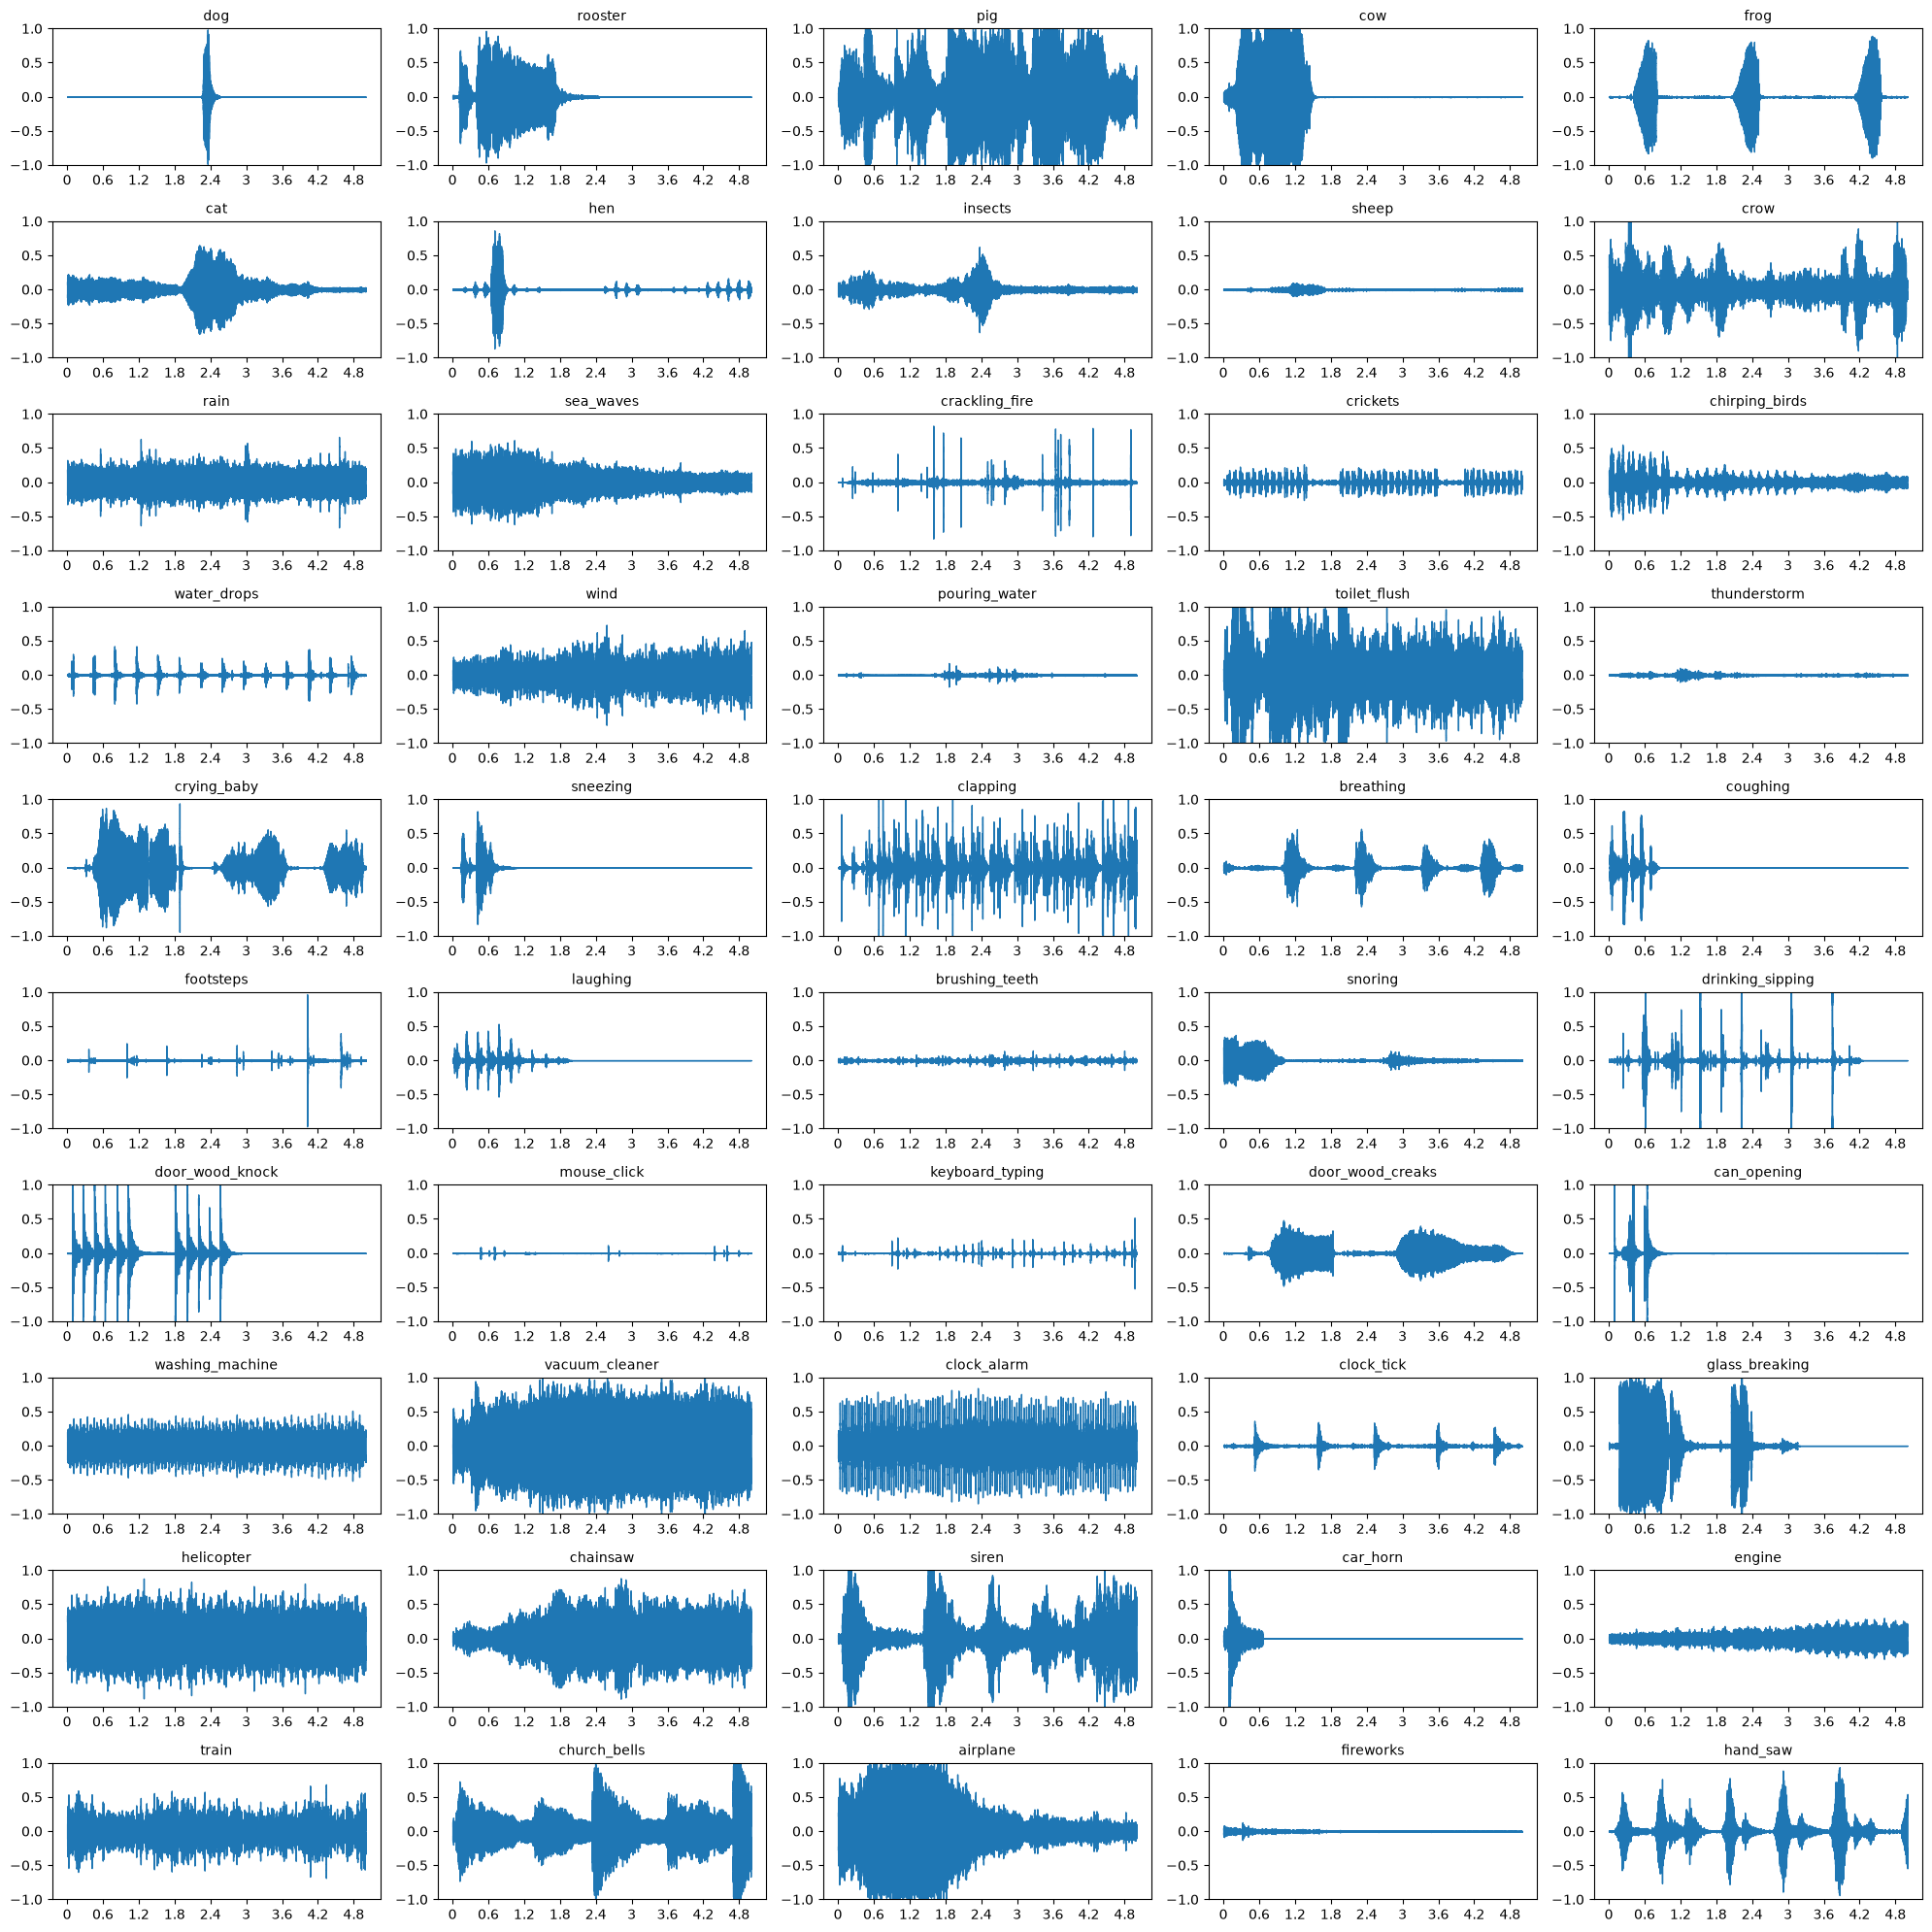

In [36]:
fig, axes = plt.subplots(10, 5, figsize=(20, 20))
for ax, r in zip(axes.ravel(), cats.itertuples()):
    y = load_audio(r.filename)
    librosa.display.waveshow(y, sr=SR, ax=ax)
    ax.set_title(r.category, fontsize=10)
    ax.set_xlabel(''); ax.set_ylim(-1, 1)
plt.tight_layout(); plt.show()

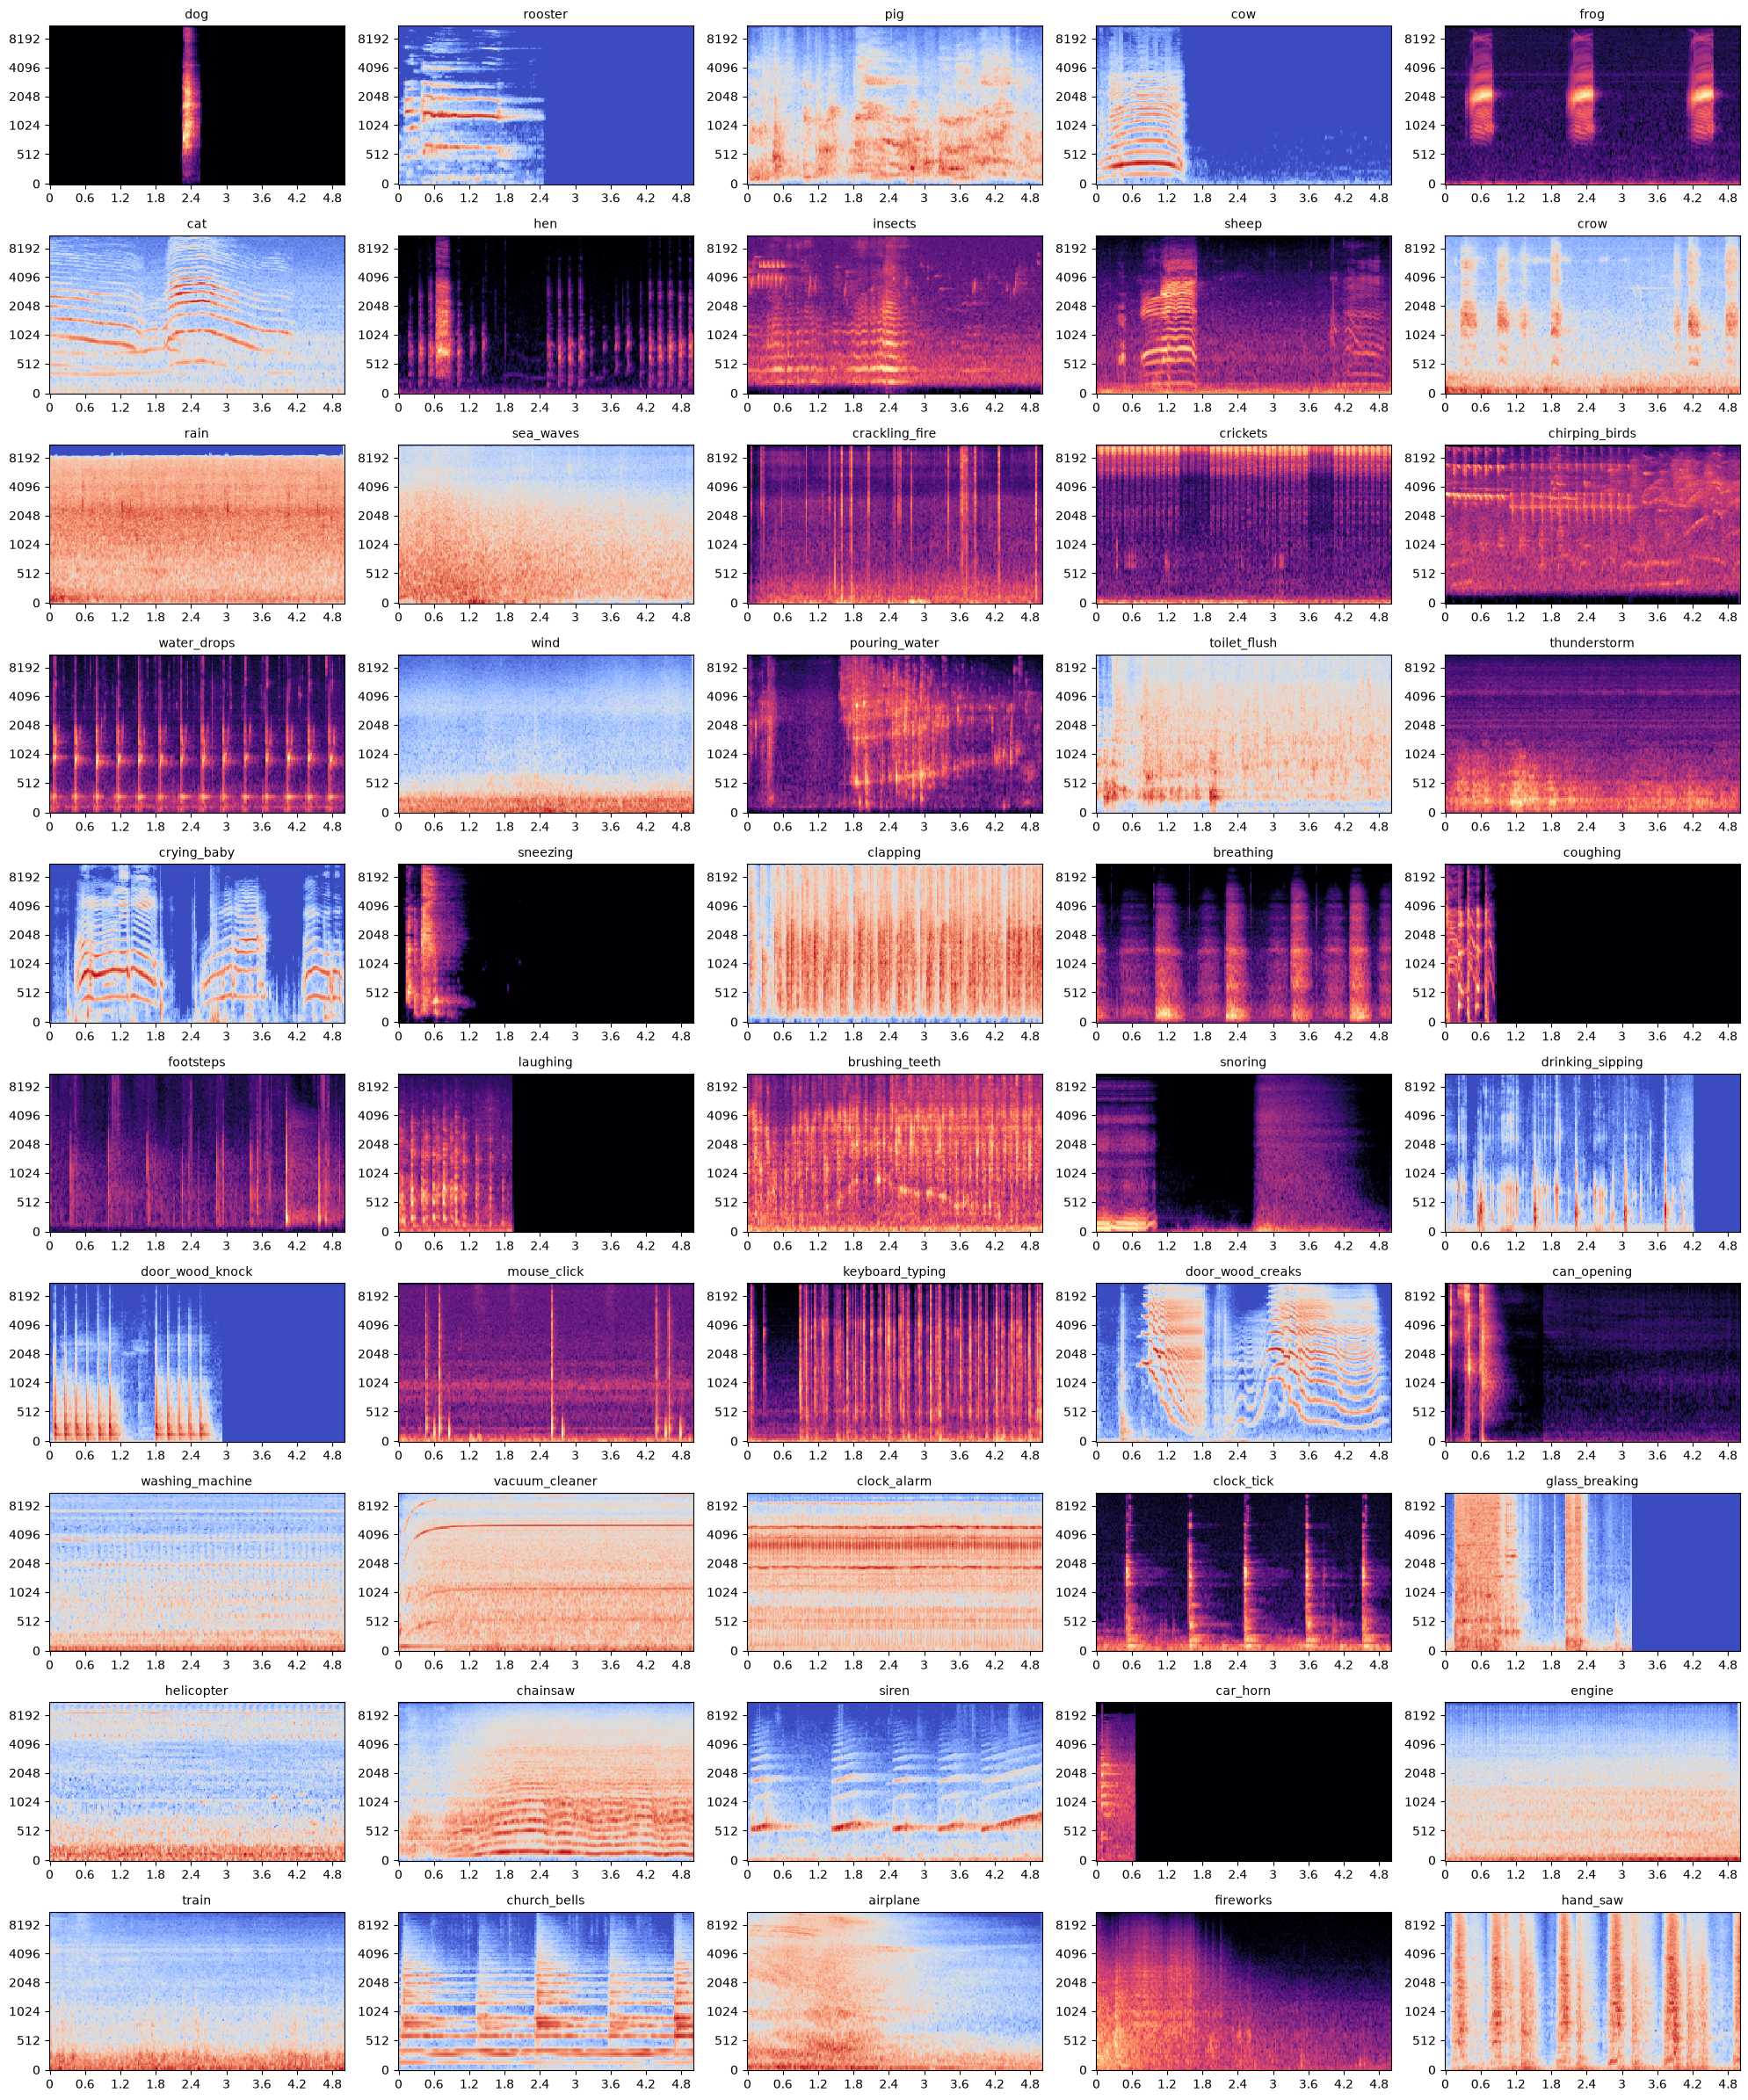

In [37]:
fig, axes = plt.subplots(10, 5, figsize=(20, 24))
for ax, r in zip(axes.ravel(), cats.itertuples()):
    S_db = logmel(load_audio(r.filename))
    librosa.display.specshow(S_db, sr=SR, hop_length=HOP,
                             x_axis='time', y_axis='mel', ax=ax)
    ax.set_title(r.category, fontsize=10)
    ax.set_xlabel(''); ax.set_ylabel('')
plt.tight_layout(); plt.show()

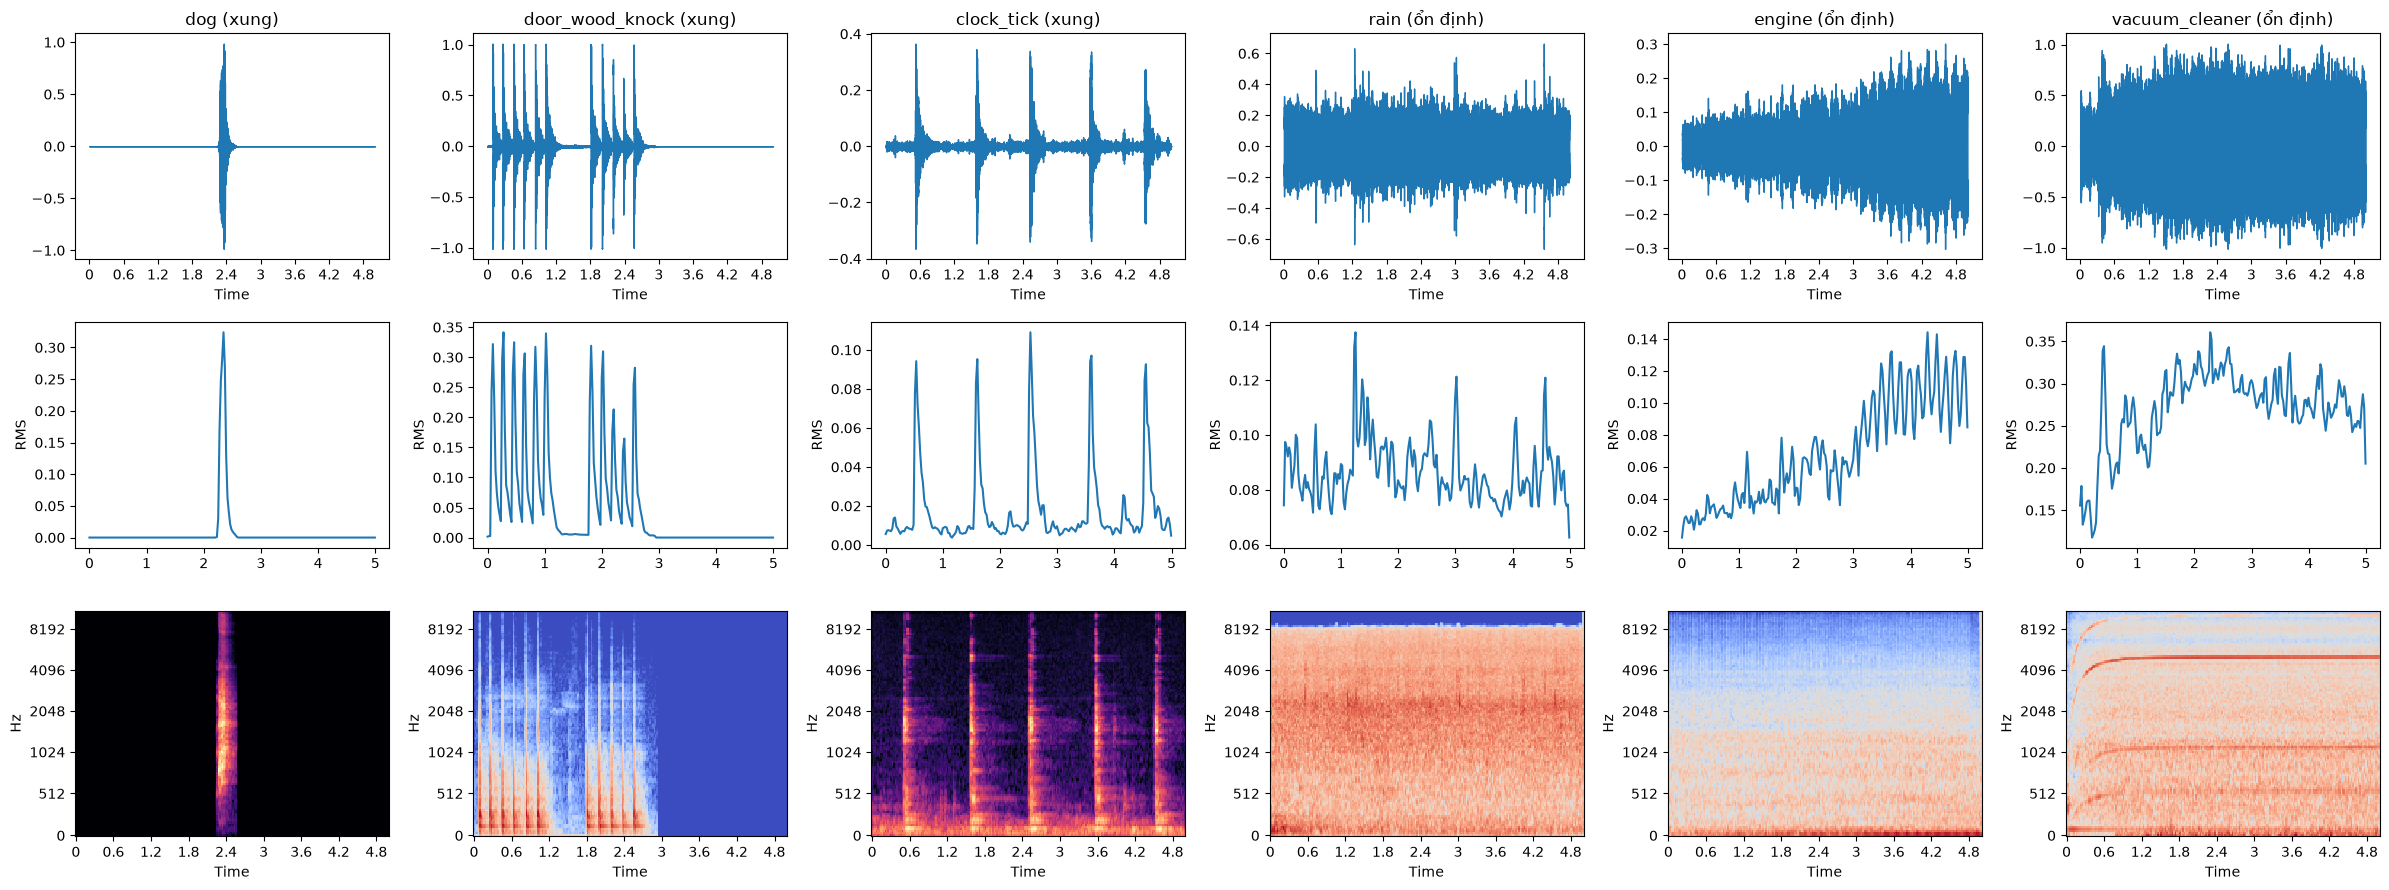

In [41]:
impulsive  = ['dog', 'door_wood_knock', 'clock_tick']
stationary = ['rain', 'engine', 'vacuum_cleaner']
groups = impulsive + stationary

fig, axes = plt.subplots(3, 6, figsize=(24, 9))
for j, c in enumerate(groups):
    f = df.loc[df.category == c, 'filename'].iloc[0]
    y = load_audio(f)
    rms = librosa.feature.rms(y=y, frame_length=N_FFT, hop_length=HOP)[0]
    t = librosa.times_like(rms, sr=SR, hop_length=HOP)

    librosa.display.waveshow(y, sr=SR, ax=axes[0, j])
    axes[0, j].set_title(f"{c} ({'xung' if c in impulsive else 'ổn định'})")
    axes[1, j].plot(t, rms); axes[1, j].set_ylabel('RMS')
    librosa.display.specshow(logmel(y), sr=SR, hop_length=HOP,
                             x_axis='time', y_axis='mel', ax=axes[2, j])
plt.tight_layout(); plt.show()